In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

print("All libraries imported successfully!")

All libraries imported successfully!


In [31]:
# Locate the project folder
PROJECT_DIR = Path.cwd().parent

# Path to the raw dataset
DATA_PATH = (
    PROJECT_DIR
    / "data"
    / "raw"
    / "WA_Fn-UseC_-Telco-Customer-Churn.csv"
)

# Load the raw data
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset loaded successfully!
Number of rows: 7043
Number of columns: 21


In [32]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [33]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [34]:
df.shape

(7043, 21)

In [35]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [36]:
df.isnull().sum().sort_values(ascending=False)

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [37]:
# Check missing values in each column
missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": (missing_values / len(df) * 100).round(2)
})

missing_summary.sort_values(
    by="Missing Values",
    ascending=False
)

,Missing Values,Missing Percentage
customerID,0,0.0
gender,0,0.0
SeniorCitizen,0,0.0
Partner,0,0.0
Dependents,0,0.0
tenure,0,0.0
PhoneService,0,0.0
MultipleLines,0,0.0
InternetService,0,0.0
OnlineSecurity,0,0.0


In [38]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())

Duplicate rows: 0
Duplicate customer IDs: 0


In [39]:
df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

In [40]:
print("Data type:", df["TotalCharges"].dtype)

# Find empty or whitespace-only values
blank_total_charges = df["TotalCharges"].astype(str).str.strip().eq("")

print("Blank TotalCharges:", blank_total_charges.sum())

# Display affected records
df.loc[blank_total_charges, ["customerID", "tenure", "TotalCharges"]]

Data type: str
Blank TotalCharges: 11


,customerID,tenure,TotalCharges
488,4472-LVYGI,0,
753,3115-CZMZD,0,
936,5709-LVOEQ,0,
1082,4367-NUYAO,0,
1340,1371-DWPAZ,0,
3331,7644-OMVMY,0,
3826,3213-VVOLG,0,
4380,2520-SGTTA,0,
5218,2923-ARZLG,0,
6670,4075-WKNIU,0,


Churn
No     5174
Yes    1869
Name: count, dtype: int64


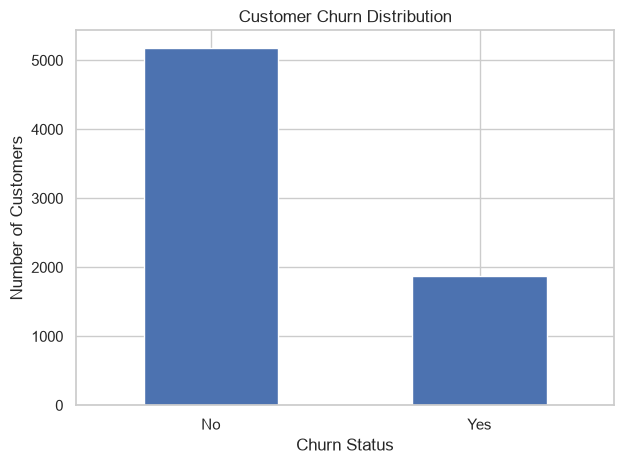

In [41]:
churn_counts = df["Churn"].value_counts()

print(churn_counts)

churn_counts.plot(
    kind="bar",
    title="Customer Churn Distribution",
    xlabel="Churn Status",
    ylabel="Number of Customers",
    rot=0
)

plt.tight_layout()
plt.show()

In [42]:
# Keep the original dataset unchanged
df_clean = df.copy()

print("Original dataset:", df.shape)
print("Working copy:", df_clean.shape)

Original dataset: (7043, 21)
Working copy: (7043, 21)


In [43]:
# Convert blank strings to missing values
df_clean["TotalCharges"] = (
    df_clean["TotalCharges"]
    .astype(str)
    .str.strip()
    .replace("", np.nan)
)

# Convert the column to numeric
df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"],
    errors="coerce"
)

print("TotalCharges data type:", df_clean["TotalCharges"].dtype)
print("Missing TotalCharges:", df_clean["TotalCharges"].isna().sum())

TotalCharges data type: float64
Missing TotalCharges: 11


In [44]:
df_clean.loc[
    df_clean["TotalCharges"].isna(),
    ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


In [45]:
# Replace missing TotalCharges with 0 for zero-tenure customers
zero_tenure_missing = (
    df_clean["TotalCharges"].isna()
    & (df_clean["tenure"] == 0)
)

df_clean.loc[zero_tenure_missing, "TotalCharges"] = 0

print("Missing TotalCharges remaining:", df_clean["TotalCharges"].isna().sum())
print("Total rows:", len(df_clean))

Missing TotalCharges remaining: 0
Total rows: 7043


In [46]:
print("Duplicate rows:", df_clean.duplicated().sum())
print("Duplicate customer IDs:", df_clean["customerID"].duplicated().sum())
print("Missing customer IDs:", df_clean["customerID"].isna().sum())
print("Missing values across all columns:", df_clean.isna().sum().sum())

df_clean.info()

Duplicate rows: 0
Duplicate customer IDs: 0
Missing customer IDs: 0
Missing values across all columns: 0
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    


In [47]:
from pathlib import Path

PROJECT_DIR = Path.cwd().parent
OUTPUT_DIR = PROJECT_DIR / "data" / "processed"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_PATH = OUTPUT_DIR / "telco_churn_cleaned.csv"

df_clean.to_csv(OUTPUT_PATH, index=False)

print("Cleaned CSV saved successfully!")
print(OUTPUT_PATH)

Cleaned CSV saved successfully!
C:\Users\monus\Desktop\customer-churn-retention-analysis\data\processed\telco_churn_cleaned.csv


In [48]:
total_customers = df_clean["customerID"].nunique()

churned_customers = (df_clean["Churn"] == "Yes").sum()
retained_customers = (df_clean["Churn"] == "No").sum()

churn_rate = churned_customers / total_customers * 100
retention_rate = retained_customers / total_customers * 100

print(f"Total customers: {total_customers:,}")
print(f"Churned customers: {churned_customers:,}")
print(f"Retained customers: {retained_customers:,}")
print(f"Churn rate: {churn_rate:.2f}%")
print(f"Retention rate: {retention_rate:.2f}%")

Total customers: 7,043
Churned customers: 1,869
Retained customers: 5,174
Churn rate: 26.54%
Retention rate: 73.46%


In [49]:
# Overall customer churn KPIs

kpi_summary = pd.DataFrame({
    "Metric": [
        "Total Customers",
        "Churned Customers",
        "Retained Customers",
        "Churn Rate (%)",
        "Retention Rate (%)"
    ],
    "Value": [
        total_customers,
        churned_customers,
        retained_customers,
        round(churn_rate, 2),
        round(retention_rate, 2)
    ]
})

kpi_summary

,Metric,Value
0,Total Customers,7043.00
1,Churned Customers,1869.00
2,Retained Customers,5174.00
3,Churn Rate (%),26.54
4,Retention Rate (%),73.46


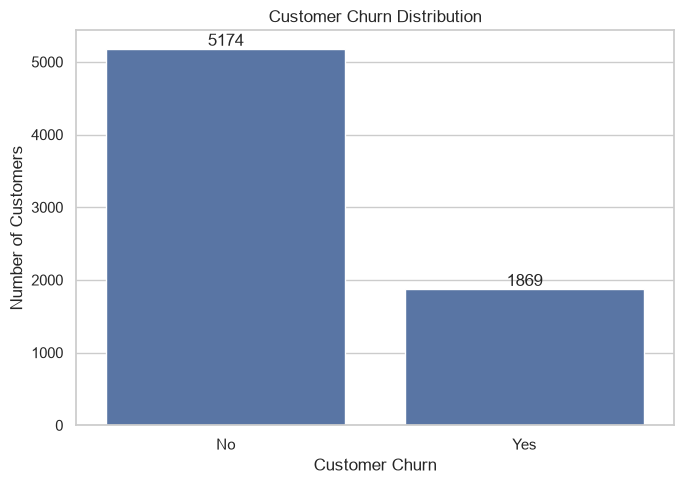

In [50]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=df_clean,
    x="Churn",
    order=["No", "Yes"]
)

plt.title("Customer Churn Distribution")
plt.xlabel("Customer Churn")
plt.ylabel("Number of Customers")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")

plt.tight_layout()
plt.show()

In [51]:
contract_churn = (
    df_clean.groupby("Contract")
    .agg(
        Total_Customers=("customerID", "nunique"),
        Churned_Customers=("Churn", lambda x: (x == "Yes").sum())
    )
)

contract_churn["Churn_Rate_%"] = (
    contract_churn["Churned_Customers"]
    / contract_churn["Total_Customers"] * 100
).round(2)

contract_churn.sort_values("Churn_Rate_%", ascending=False)

,Total_Customers,Churned_Customers,Churn_Rate_%
Contract,,,
Month-to-month,3875,1655,42.71
One year,1473,166,11.27
Two year,1695,48,2.83


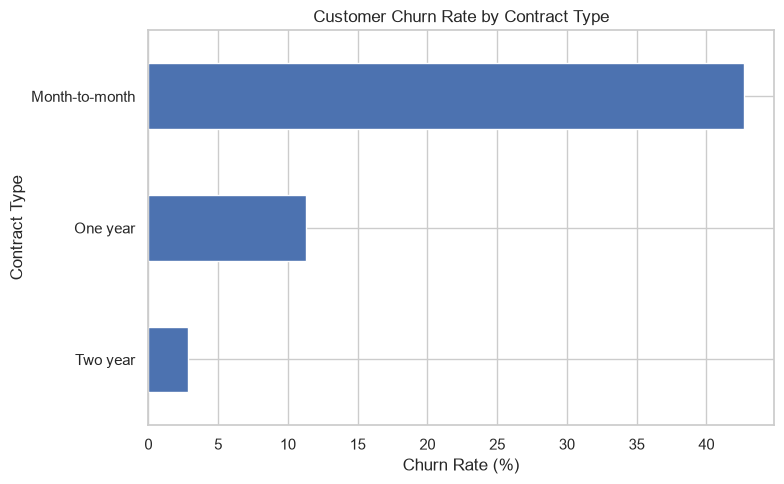

In [52]:
contract_churn["Churn_Rate_%"].sort_values().plot(
    kind="barh",
    figsize=(8, 5)
)

plt.title("Customer Churn Rate by Contract Type")
plt.xlabel("Churn Rate (%)")
plt.ylabel("Contract Type")
plt.tight_layout()
plt.show()

In [53]:
df_clean["Tenure_Group"] = pd.cut(
    df_clean["tenure"],
    bins=[-1, 6, 12, 24, 48, 72],
    labels=[
        "0–6 months",
        "7–12 months",
        "13–24 months",
        "25–48 months",
        "49–72 months"
    ]
)

tenure_churn = (
    df_clean.groupby("Tenure_Group", observed=False)
    .agg(
        Total_Customers=("customerID", "nunique"),
        Churned_Customers=("Churn", lambda x: (x == "Yes").sum())
    )
)

tenure_churn["Churn_Rate_%"] = (
    tenure_churn["Churned_Customers"]
    / tenure_churn["Total_Customers"] * 100
).round(2)

tenure_churn

,Total_Customers,Churned_Customers,Churn_Rate_%
Tenure_Group,,,
0–6 months,1481,784,52.94
7–12 months,705,253,35.89
13–24 months,1024,294,28.71
25–48 months,1594,325,20.39
49–72 months,2239,213,9.51


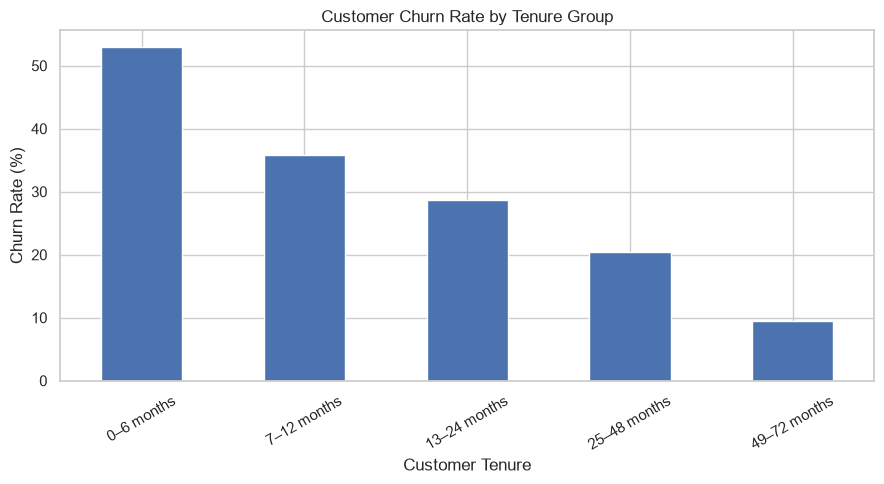

In [54]:
tenure_churn["Churn_Rate_%"].plot(
    kind="bar",
    figsize=(9, 5),
    rot=30
)

plt.title("Customer Churn Rate by Tenure Group")
plt.xlabel("Customer Tenure")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.show()

In [55]:
service_churn = (
    df_clean.groupby("InternetService")
    .agg(
        Total_Customers=("customerID", "nunique"),
        Churned_Customers=("Churn", lambda x: (x == "Yes").sum())
    )
)

service_churn["Churn_Rate_%"] = (
    service_churn["Churned_Customers"]
    / service_churn["Total_Customers"] * 100
).round(2)

service_churn.sort_values("Churn_Rate_%", ascending=False)

,Total_Customers,Churned_Customers,Churn_Rate_%
InternetService,,,
Fiber optic,3096,1297,41.89
DSL,2421,459,18.96
No,1526,113,7.40


In [56]:
df_clean.groupby("Churn")["MonthlyCharges"].agg(
    ["count", "mean", "median"]
).round(2)

,count,mean,median
Churn,,,
No,5174,61.27,64.43
Yes,1869,74.44,79.65


In [57]:
payment_churn = (
    df_clean.groupby("PaymentMethod")
    .agg(
        Total_Customers=("customerID", "nunique"),
        Churned_Customers=("Churn", lambda x: (x == "Yes").sum())
    )
)

payment_churn["Churn_Rate_%"] = (
    payment_churn["Churned_Customers"]
    / payment_churn["Total_Customers"] * 100
).round(2)

payment_churn.sort_values("Churn_Rate_%", ascending=False)

,Total_Customers,Churned_Customers,Churn_Rate_%
PaymentMethod,,,
Electronic check,2365,1071,45.29
Mailed check,1612,308,19.11
Bank transfer (automatic),1544,258,16.71
Credit card (automatic),1522,232,15.24


In [58]:
support_churn = (
    df_clean.groupby("TechSupport")
    .agg(
        Total_Customers=("customerID", "nunique"),
        Churned_Customers=("Churn", lambda x: (x == "Yes").sum())
    )
)

support_churn["Churn_Rate_%"] = (
    support_churn["Churned_Customers"]
    / support_churn["Total_Customers"] * 100
).round(2)

support_churn.sort_values("Churn_Rate_%", ascending=False)

,Total_Customers,Churned_Customers,Churn_Rate_%
TechSupport,,,
No,3473,1446,41.64
Yes,2044,310,15.17
No internet service,1526,113,7.40


In [59]:

print("Cleaned dataset available:", "df_clean" in globals())

if "df_clean" in globals():
    print("Dataset shape:", df_clean.shape)
    print("Columns:", df_clean.columns.tolist())


Cleaned dataset available: True
Dataset shape: (7043, 22)
Columns: ['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn', 'Tenure_Group']


In [60]:

print(df_clean.columns.tolist())


['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn', 'Tenure_Group']


In [61]:

# Analyze customer churn by contract type and tenure

contract_tenure = (
    df_clean.groupby(
        ["Contract", "Tenure_Group"],
        observed=True
    )
    .agg(
        Total_Customers=("customerID", "nunique"),
        Churned_Customers=(
            "Churn",
            lambda x: (x == "Yes").sum()
        )
    )
    .reset_index()
)

contract_tenure["Churn_Rate_%"] = (
    contract_tenure["Churned_Customers"]
    / contract_tenure["Total_Customers"]
    * 100
).round(2)

# Exclude groups with fewer than 30 customers
contract_tenure = contract_tenure[
    contract_tenure["Total_Customers"] >= 30
]

# Show the highest churn rates first
contract_tenure = contract_tenure.sort_values(
    "Churn_Rate_%",
    ascending=False
)

display(contract_tenure)


,Contract,Tenure_Group,Total_Customers,Churned_Customers,Churn_Rate_%
0,Month-to-month,0–6 months,1413,780,55.20
1,Month-to-month,7–12 months,581,244,42.00
2,Month-to-month,13–24 months,737,278,37.72
3,Month-to-month,25–48 months,802,264,32.92
4,Month-to-month,49–72 months,342,89,26.02
9,One year,49–72 months,634,82,12.93
8,One year,25–48 months,518,55,10.62
6,One year,7–12 months,85,9,10.59
5,One year,0–6 months,39,4,10.26
7,One year,13–24 months,197,16,8.12


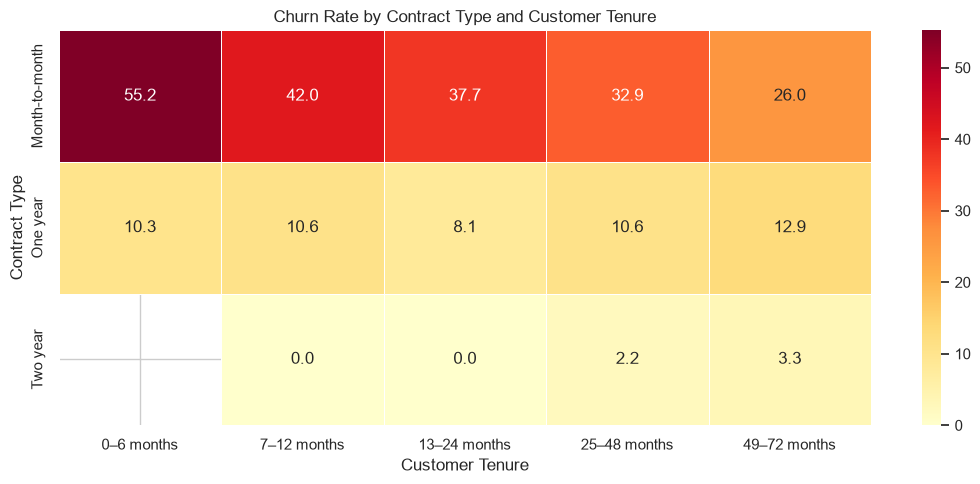

In [62]:

import seaborn as sns
import matplotlib.pyplot as plt

heatmap_data = contract_tenure.pivot(
    index="Contract",
    columns="Tenure_Group",
    values="Churn_Rate_%"
)

plt.figure(figsize=(11, 5))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    linewidths=0.5
)

plt.title("Churn Rate by Contract Type and Customer Tenure")
plt.xlabel("Customer Tenure")
plt.ylabel("Contract Type")
plt.tight_layout()
plt.show()


In [63]:

# Top 10 customer segments by churn rate

top_segments = contract_tenure[
    [
        "Contract",
        "Tenure_Group",
        "Total_Customers",
        "Churned_Customers",
        "Churn_Rate_%"
    ]
].head(10)

display(top_segments)


,Contract,Tenure_Group,Total_Customers,Churned_Customers,Churn_Rate_%
0,Month-to-month,0–6 months,1413,780,55.20
1,Month-to-month,7–12 months,581,244,42.00
2,Month-to-month,13–24 months,737,278,37.72
3,Month-to-month,25–48 months,802,264,32.92
4,Month-to-month,49–72 months,342,89,26.02
9,One year,49–72 months,634,82,12.93
8,One year,25–48 months,518,55,10.62
6,One year,7–12 months,85,9,10.59
5,One year,0–6 months,39,4,10.26
7,One year,13–24 months,197,16,8.12


In [64]:

print("CUSTOMER CHURN BUSINESS INSIGHTS")
print("=" * 40)

highest_risk = contract_tenure.iloc[0]

print(
    f"\nHighest-risk segment: "
    f"{highest_risk['Contract']} contract, "
    f"{highest_risk['Tenure_Group']} tenure"
)

print(f"Customers in segment: {highest_risk['Total_Customers']}")
print(f"Customers churned: {highest_risk['Churned_Customers']}")
print(f"Churn rate: {highest_risk['Churn_Rate_%']}%")

print("\nRECOMMENDED ACTIONS")
print("1. Review onboarding and early customer experience.")
print("2. Investigate reasons for churn in high-risk segments.")
print("3. Test targeted retention offers and measure their impact.")


CUSTOMER CHURN BUSINESS INSIGHTS

Highest-risk segment: Month-to-month contract, 0–6 months tenure
Customers in segment: 1413
Customers churned: 780
Churn rate: 55.2%

RECOMMENDED ACTIONS
1. Review onboarding and early customer experience.
2. Investigate reasons for churn in high-risk segments.
3. Test targeted retention offers and measure their impact.


In [65]:

import os

# Create an output folder
os.makedirs("../outputs", exist_ok=True)

# Export the combined contract and tenure analysis
contract_tenure.to_csv(
    "../outputs/contract_tenure_churn.csv",
    index=False
)

# Export the top 10 highest-risk segments
top_segments.to_csv(
    "../outputs/top_churn_segments.csv",
    index=False
)

print("Analysis results exported successfully!")
print("Files saved in the outputs folder.")


Analysis results exported successfully!
Files saved in the outputs folder.


In [66]:

print(os.path.abspath("../outputs"))
print(os.listdir("../outputs"))


C:\Users\monus\Desktop\customer-churn-retention-analysis\outputs
['contract_tenure_churn.csv', 'top_churn_segments.csv']
